# Klasifikasi Multikelas: Car Evaluation

Dataset Car Evaluation diturunkan dari model struktur keputusan hierarkis untuk menilai kelayakan pembelian mobil berdasarkan enam atribut evaluasi. Data ini bersumber dari UCI Machine Learning Repository.

- Nama dataset: Car Evaluation
- Sumber data: UCI Machine Learning Repository (ID: 19)
- Link dataset: https://archive.ics.uci.edu/dataset/19/car+evaluation
- Dimensi data: 1.728 baris dan 7 kolom (6 atribut mobil dan 1 kolom target)
- Variabel target: Kolom `class` yang memuat 4 tingkat penerimaan kelayakan mobil: unacc, acc, good, dan vgood

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

car = fetch_ucirepo(id=19)
X = car.data.features
y = car.data.targets
df = pd.concat([X, y], axis=1)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc



Tipe data:
buying      str
maint       str
doors       str
persons     str
lug_boot    str
safety      str
class       str
dtype: object


Jumlah kelas: 4 => multikelas: True

Distribusi kelas:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


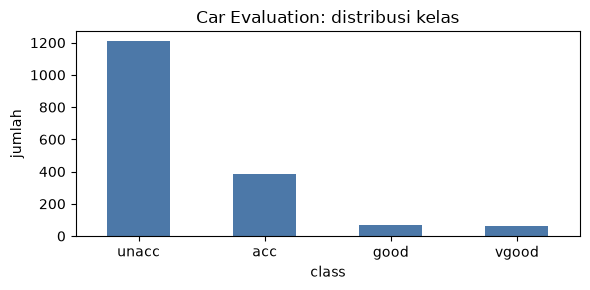

In [2]:
import matplotlib.pyplot as plt

def plot_dist(y, title, rot=0):
    ax = pd.Series(y).value_counts().plot(kind="bar", figsize=(6, 3), color="#4C78A8")
    ax.set_title(title)
    ax.set_ylabel("jumlah")
    plt.xticks(rotation=rot)
    plt.tight_layout()
    plt.show()

target_col = "class"

print("Jumlah kelas:", df[target_col].nunique(), "=> multikelas:", df[target_col].nunique() > 2)
print("\nDistribusi kelas:")
print(df[target_col].value_counts())
plot_dist(df[target_col], "Car Evaluation: distribusi kelas")

In [3]:
assert df[target_col].nunique() == 4, f"Nilai unik harus 4, didapat: {df[target_col].nunique()}"
assert df[target_col].nunique() > 2, "Harus lebih dari 2 kelas untuk multikelas"
assert set(df[target_col].unique()) == {"unacc", "acc", "good", "vgood"}, "Label target tidak sesuai"
assert df[target_col].isnull().sum() == 0, "Target mengandung nilai null"
assert df.shape == (1728, 7), f"Bentuk dataframe tidak sesuai: {df.shape}"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Car Evaluation terbukti merupakan klasifikasi multikelas karena kolom target `class` memiliki 4 nilai unik yang tidak tumpang tindih:
- unacc (unacceptable): 1.210 baris
- acc (acceptable): 384 baris
- good: 69 baris
- vgood (very good): 65 baris

Total sampel adalah 1.728 baris dan tiap baris hanya memiliki satu tingkat evaluasi kelayakan.